In [1]:
# -----------------------------------------------------------------------
# 0. Libraries and Reproducibility setup
# -----------------------------------------------------------------------

import sys
import os
import warnings
import numpy as np
import matplotlib
import scipy
import sklearn
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (Matern, ConstantKernel, WhiteKernel)
from scipy.stats import norm, skew, spearmanr, qmc
from scipy.optimize import minimize
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

SEED = 42
rng = np.random.default_rng(SEED)
np.random.seed(SEED)
SK_RANDOM_STATE = np.random.RandomState(SEED)  # sklearn wants a RandomState

print("=" * 100)
print("Software and Libraries used")
print("=" * 100)
print(f"  python      : {sys.version.split()[0]}")
print(f"  numpy       : {np.__version__}")
print(f"  scipy       : {scipy.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
print(f"  matplotlib  : {matplotlib.__version__}")
print(f"  SEED        : {SEED}")
print()

# ---------------------------------------------------------------- 
# Figures settings
# ---------------------------------------------------------------- 
SURFACE, INK, INK2, MUTED, GRIDC = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e6e5e1"
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
BLUE, ORANGE, AQUA, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#e87ba4"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "text.color": INK, "axes.edgecolor": MUTED, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRIDC, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

Software and Libraries used
  python      : 3.13.9
  numpy       : 2.3.5
  scipy       : 1.16.3
  scikit-learn: 1.9.0
  matplotlib  : 3.11.1
  SEED        : 42



n = 30 (20 initial + 10 queried); newest x = [0.472359 0.451118 0.460178 0.628744 0.078485], y = -0.424866
Best observed: row 27, x = [0.434229 0.453969 0.417472 0.730647 0.125786], y = -0.404822; skew of y = -0.28




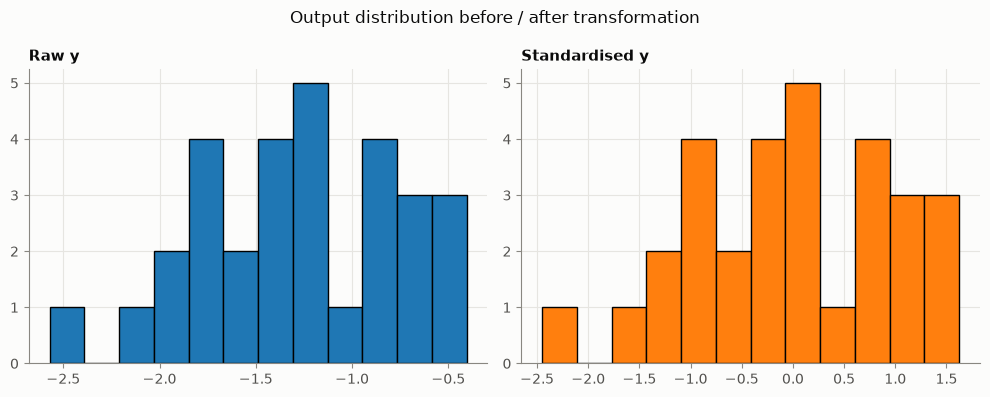

In [2]:
# ---------------------------------------------------------------------------
# 1. DATA
# ---------------------------------------------------------------------------
X = np.load('..\Function_6_Data\Week_11_Data/F6_Week_11_inputs.npy')
y = np.load('..\Function_6_Data\Week_11_Data/F6_Week_11_outputs.npy')
n, d = X.shape
N_INITIAL = 20
best = int(np.argmax(y))
xb = X[best]

ym, ys = y.mean(), y.std()
z = (y - ym) / ys
print(f"n = {n} ({N_INITIAL} initial + {n - N_INITIAL} queried); newest x = {np.round(X[-1], 6)}, y = {y[-1]:.6f}")
print(f"Best observed: row {best}, x = {np.round(xb, 6)}, y = {y[best]:.6f}; skew of y = {skew(y):.2f}")

print('\n')
# Fig 1: target distribution
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(y, bins=12, color="#1f77b4", edgecolor="k")
axes[0].set_title("Raw y")
axes[1].hist(z, bins=12, color="#ff7f0e", edgecolor="k")
axes[1].set_title("Standardised y")
fig.suptitle("Output distribution before / after transformation")
fig.tight_layout()


GP ARD kernel: 1.71**2 * Matern(length_scale=[0.955, 0.741, 1.06, 1.25, 2.37], nu=2.5) + WhiteKernel(noise_level=0.000236)
GP isotropic kernel: 1.33**2 * Matern(length_scale=0.848, nu=2.5) + WhiteKernel(noise_level=0.000252)

LEAVE-ONE-OUT (hyperparameters fixed at the full fit)
  GP isotropic               RMSE/std=0.475  Spearman=0.903  top-6 RMSE=0.045  95% coverage=0.97  week-10 point predicted -0.427 (actual -0.425)
  GP ARD                     RMSE/std=0.379  Spearman=0.928  top-6 RMSE=0.029  95% coverage=1.00  week-10 point predicted -0.420 (actual -0.425)
  additive quadratic         RMSE/std=0.281  Spearman=0.949  top-6 RMSE=0.089  95% coverage=nan  week-10 point predicted -0.509 (actual -0.425)
  quadratic + GP isotropic   RMSE/std=0.275  Spearman=0.953  top-6 RMSE=0.047  95% coverage=0.77  week-10 point predicted -0.434 (actual -0.425)
  quadratic + GP ARD         RMSE/std=0.257  Spearman=0.956  top-6 RMSE=0.038  95% coverage=0.80  week-10 point predicted -0.457 (actual -0.

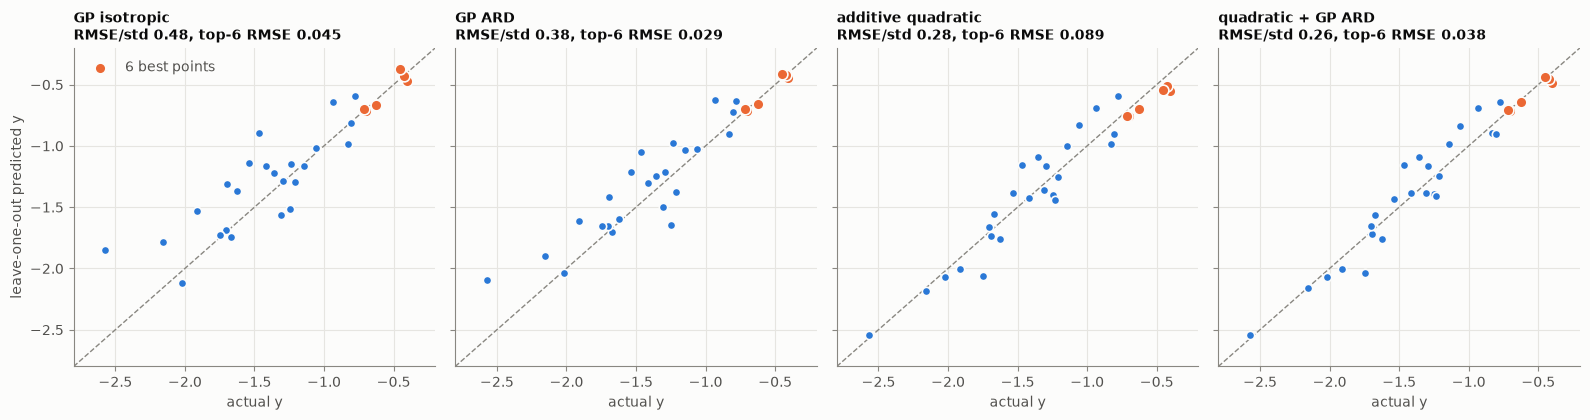

In [3]:
# ---------------------------------------------------------------------------
# SURROGATE MODEL: re-run ARD vs isotropic model selection
# ---------------------------------------------------------------------------

def quad_features(Z):
    Z = np.atleast_2d(Z)
    return np.c_[np.ones(len(Z)), Z, Z ** 2]

def kernel(ard):
    return (ConstantKernel(1.0, (1e-2, 1e2)) * Matern(length_scale=np.ones(d) if ard else 1.0,
                                         length_scale_bounds=(1e-2, 1e1), nu=2.5)
            + WhiteKernel(1e-2, (1e-5, 1e0)))

class GP:
    """GP on standardised y; predictions in raw y units."""
    def __init__(self, ard, k=None):
        self.ard, self.k = ard, k
    def fit(self, Xt, yt):
        self.m, self.s = yt.mean(), yt.std()
        self.g = GaussianProcessRegressor(kernel=self.k or kernel(self.ard), alpha=1e-10,
                                          optimizer=None if self.k else "fmin_l_bfgs_b",
                                          n_restarts_optimizer=0 if self.k else 20,
                                          random_state=SEED).fit(Xt, (yt - self.m) / self.s)
        return self
    
    def predict(self, Z):
        mu, sd = self.g.predict(np.atleast_2d(Z), return_std=True)
        return mu * self.s + self.m, sd * self.s
   
    def refit_fixed(self):
        return GP(self.ard, self.g.kernel_)

class Hybrid:
    """Additive quadratic trend plus a GP on its residuals."""
    def __init__(self, ard, k=None):
        self.ard, self.k = ard, k
    def fit(self, Xt, yt):
        self.c = np.linalg.lstsq(quad_features(Xt), yt, rcond=None)[0]
        self.r = GP(self.ard, self.k).fit(Xt, yt - quad_features(Xt) @ self.c)
        return self
    def predict(self, Z):
        mu, sd = self.r.predict(Z)
        return mu + quad_features(Z) @ self.c, sd
    def refit_fixed(self):
        return Hybrid(self.ard, self.r.g.kernel_)

class Quad:
    def fit(self, Xt, yt):
        self.c = np.linalg.lstsq(quad_features(Xt), yt, rcond=None)[0]
        return self
    def predict(self, Z):
        return quad_features(Z) @ self.c, np.zeros(len(np.atleast_2d(Z)))
    def refit_fixed(self):
        return Quad()

models = {"GP isotropic": GP(False).fit(X, y), "GP ARD": GP(True).fit(X, y),
          "additive quadratic": Quad().fit(X, y),
          "quadratic + GP isotropic": Hybrid(False).fit(X, y), 
          "quadratic + GP ARD": Hybrid(True).fit(X, y)}
print(f"\nGP ARD kernel: {models['GP ARD'].g.kernel_}")
print(f"GP isotropic kernel: {models['GP isotropic'].g.kernel_}")

top = np.argsort(-y)[:6]
loos = {}
print("\nLEAVE-ONE-OUT (hyperparameters fixed at the full fit)")
for name, mdl in models.items():
    mu, sd = np.empty(n), np.empty(n)
    for i in range(n):
        keep = np.arange(n) != i
        a, b = mdl.refit_fixed().fit(X[keep], y[keep]).predict(X[i:i + 1])
        mu[i], sd[i] = a[0], b[0]
    loos[name] = (mu, sd)
    cover = np.mean(np.abs((y - mu) / np.maximum(sd, 1e-12)) < 1.96) if name != "additive quadratic" else np.nan
    print(f"  {name:26s} RMSE/std={np.sqrt(np.mean((y - mu) ** 2)) / ys:.3f}  Spearman={spearmanr(y, mu)[0]:.3f}  "
          f"top-6 RMSE={np.sqrt(np.mean((y[top] - mu[top]) ** 2)):.3f}  95% coverage={cover:.2f}  "
          f"week-10 point predicted {mu[-1]:.3f} (actual {y[-1]:.3f})")
print('\n')

# Fig 2: LOO predicted vs actual for four models
show = ["GP isotropic", "GP ARD", "additive quadratic", "quadratic + GP ARD"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4.3), sharey=True)
lim = [-2.8, -0.2]
for ax, name in zip(axes, show):
    mu, sd = loos[name]
    ax.plot(lim, lim, color=MUTED, lw=1, ls="--")
    ax.scatter(y, mu, s=36, color=PAL[0], edgecolor=SURFACE, linewidth=1.2, zorder=3)
    ax.scatter(y[top], mu[top], s=60, color=PAL[1], edgecolor=SURFACE, linewidth=1.2, zorder=4, label="6 best points")
    ax.set_xlim(lim); ax.set_ylim(lim); ax.set_xlabel("actual y")
    ax.set_title(f"{name}\nRMSE/std {np.sqrt(np.mean((y - mu) ** 2)) / ys:.2f}, top-6 RMSE {np.sqrt(np.mean((y[top] - mu[top]) ** 2)):.3f}", fontsize=10)
axes[0].set_ylabel("leave-one-out predicted y")
axes[0].legend(frameon=False, loc="upper left", labelcolor=INK2)
fig.tight_layout()

In [4]:
# ---------------------------------------------------------------- 
# Candidates
# ----------------------------------------------------------------

gA = models["GP ARD"]
nv = gA.g.kernel_.k2.noise_level
mu_tr, _ = gA.predict(X)
f_inc = (mu_tr.max() - gA.m) / gA.s
S = qmc.Sobol(d, seed=1).random(2 ** 14)

def ei_ard(Z, xi=0.0):
    m, s = gA.g.predict(np.atleast_2d(Z), return_std=True)
    s = np.sqrt(np.maximum(s ** 2 - nv, 1e-18))
    zz = (m - f_inc - xi) / s
    return (m - f_inc - xi) * norm.cdf(zz) + s * norm.pdf(zz)

def box_argmax(fn, r):
    lo, hi = np.clip(xb - r, 0, 1), np.clip(xb + r, 0, 1)
    Z = lo + S * (hi - lo)
    v = fn(Z); x0 = Z[v.argmax()]
    res = minimize(lambda q: -fn(q[None])[0], x0, bounds=list(zip(lo, hi)), method="L-BFGS-B")
    return res.x if -res.fun >= v.max() else x0

cq = models["additive quadratic"].c
x_quad = np.clip(-cq[1:d + 1] / (2 * cq[d + 1:]), 0, 1)
x_ard_full = box_argmax(lambda Z: ei_ard(Z, 0.01), 1.0)
cands = {
    "A: EI, isotropic GP (week-10 script)": np.array([0.435345, 0.408344, 0.397930, 0.674299, 0.161054]),
    "B: EI, ARD GP (full domain)": x_ard_full,
    "C: EI, ARD GP (±0.1 box)": box_argmax(lambda Z: ei_ard(Z, 0.0), 0.1),
    "D: half-step to B": xb + 0.5 * (x_ard_full - xb),
    "E: additive-quadratic peak": x_quad,
}
pred = {}
print("\nCANDIDATES: predicted y by each model (current best observed = %.4f)" % y.max())
for name, xc in cands.items():
    pred[name] = {k: m.predict(xc)[0][0] for k, m in models.items()}
    print(f"  {name:38s} x = ({', '.join(f'{v:.6f}' for v in xc)})  dist {np.linalg.norm(xc - xb):.3f}  "
          + "  ".join(f"{k}={v:.3f}" for k, v in pred[name].items()))
print('\n')
print(f"Reference: each model at the best observed point: "
      + "\n".join(f"{k}={m.predict(xb)[0][0]:.3f}" for k, m in models.items()))



CANDIDATES: predicted y by each model (current best observed = -0.4048)
  A: EI, isotropic GP (week-10 script)   x = (0.435345, 0.408344, 0.397930, 0.674299, 0.161054)  dist 0.083  GP isotropic=-0.409  GP ARD=-0.452  additive quadratic=-0.551  quadratic + GP isotropic=-0.454  quadratic + GP ARD=-0.543
  B: EI, ARD GP (full domain)            x = (0.448788, 0.401912, 0.482808, 0.786485, 0.000000)  dist 0.162  GP isotropic=-0.488  GP ARD=-0.299  additive quadratic=-0.442  quadratic + GP isotropic=-0.398  quadratic + GP ARD=-0.424
  C: EI, ARD GP (±0.1 box)               x = (0.447405, 0.403182, 0.483007, 0.788085, 0.025786)  dist 0.143  GP isotropic=-0.471  GP ARD=-0.312  additive quadratic=-0.452  quadratic + GP isotropic=-0.397  quadratic + GP ARD=-0.433
  D: half-step to B                      x = (0.441509, 0.427941, 0.450140, 0.758566, 0.062893)  dist 0.081  GP isotropic=-0.430  GP ARD=-0.341  additive quadratic=-0.477  quadratic + GP isotropic=-0.388  quadratic + GP ARD=-0.416
  E

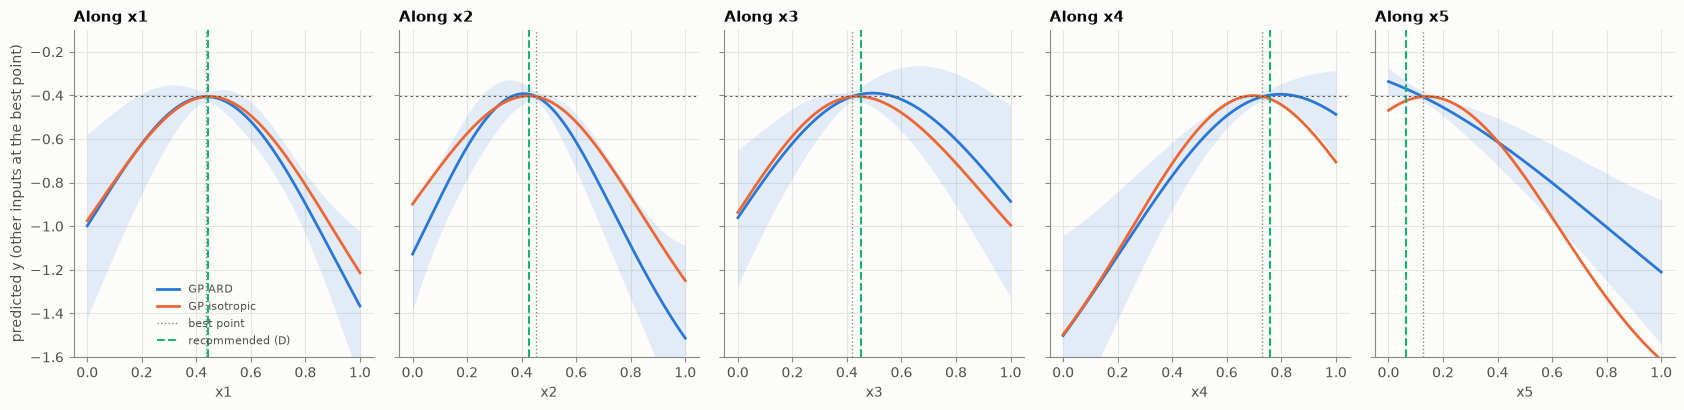

In [5]:
# Fig 3: slices of the ARD and isotropic GPs through the best point
fig, axes = plt.subplots(1, d, figsize=(17, 4.2), sharey=True)
xs = np.linspace(0, 1, 200)
xD = cands["D: half-step to B"]
for j, ax in enumerate(axes):
    Z = np.tile(xb, (len(xs), 1)); Z[:, j] = xs
    for name, col in [("GP ARD", PAL[0]), ("GP isotropic", PAL[1])]:
        m, s = models[name].predict(Z)
        ax.plot(xs, m, color=col, lw=2, label=name)
        if name == "GP ARD":
            ax.fill_between(xs, m - 2 * s, m + 2 * s, color=col, alpha=0.12, lw=0)
    ax.axvline(xb[j], color=MUTED, lw=1, ls=":", label="best point")
    ax.axvline(xD[j], color=PAL[2], lw=1.5, ls="--", label="recommended (D)")
    ax.axhline(y.max(), color=INK2, lw=0.8, ls=(0, (2, 3)))
    ax.set_xlabel(f"x{j + 1}"); ax.set_title(f"Along x{j + 1}"); ax.set_ylim(-1.6, -0.1)
axes[0].set_ylabel("predicted y (other inputs at the best point)")
axes[0].legend(frameon=False, loc="lower center", fontsize=8, labelcolor=INK2)
fig.tight_layout()

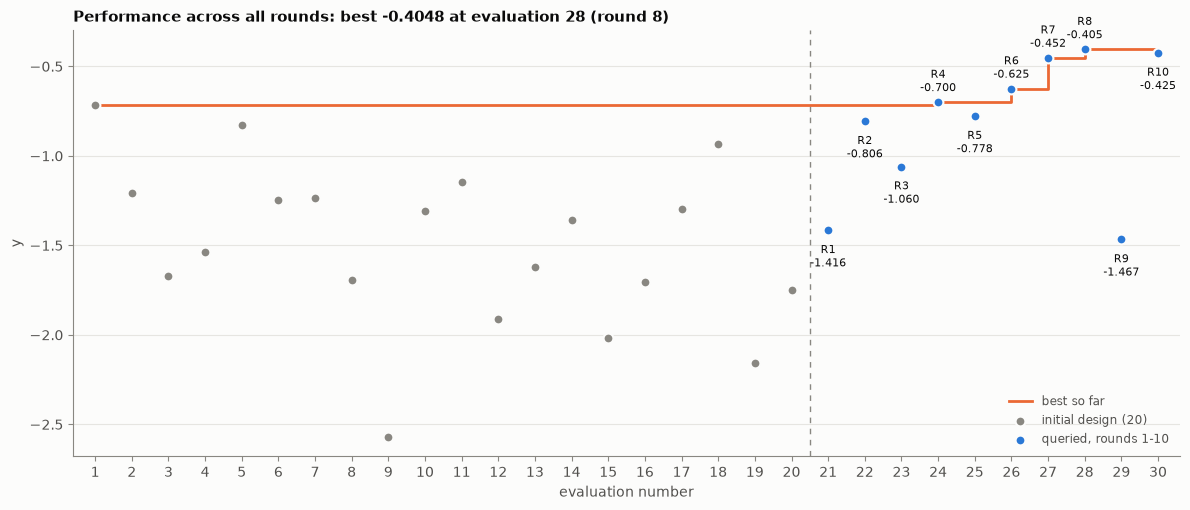

In [6]:
# Fig 5: performance across all rounds
idx = np.arange(1, n + 1)
bsf = np.maximum.accumulate(np.r_[np.full(N_INITIAL, y[:N_INITIAL].max()), y[N_INITIAL:]])
fig, ax = plt.subplots(figsize=(12, 5.2))
ax.axvline(N_INITIAL + 0.5, color=MUTED, lw=1, ls=(0, (4, 4)))
ax.step(idx, bsf, where="post", color=PAL[1], lw=2, label="best so far", zorder=2)
ax.scatter(idx[:N_INITIAL], y[:N_INITIAL], s=50, color=MUTED, edgecolor=SURFACE, linewidth=1.5, label=f"initial design ({N_INITIAL})", zorder=3)
ax.scatter(idx[N_INITIAL:], y[N_INITIAL:], s=50, color=PAL[0], edgecolor=SURFACE, linewidth=1.5, label=f"queried, rounds 1-{n - N_INITIAL}", zorder=3)
for i in range(N_INITIAL, n):
    ax.annotate(f"R{i - N_INITIAL + 1}\n{y[i]:.3f}", (idx[i], y[i]), xytext=(0, 8 if y[i] >= bsf[i] else -26),
                textcoords="offset points", ha="center", fontsize=8, color=INK)
ax.set_xticks(idx); ax.set_xlim(0.4, n + 0.6); ax.grid(axis="x", visible=False)
ax.set_xlabel("evaluation number"); ax.set_ylabel("y")
ax.set_title(f"Performance across all rounds: best {y.max():.4f} at evaluation {best + 1} (round {best - N_INITIAL + 1})")
ax.legend(frameon=False, loc="lower right", fontsize=8.5, labelcolor=INK2)
fig.tight_layout()